# Telecom Customer Churn Analysis (Python – Pandas, NumPy, Matplotlib)

**Author:** Aswinkumar K C  |  **Tools:** Python, Pandas, NumPy, Matplotlib, Jupyter Notebook

## Business problem
A telecom company is losing customers every month. Acquiring a new customer costs far more than keeping an existing one,
so the retention team wants to know **who is leaving, why, and how much monthly revenue is at risk**.

## Objectives
1. Clean the raw customer data (duplicates, blanks, missing values, inconsistent text).
2. Engineer useful features (tenure groups, number of services, charge segments).
3. Explore churn drivers with Pandas, NumPy and Matplotlib.
4. Turn the findings into clear recommendations for the business.

> The dataset is **simulated** (see `generate_dataset.py`) with the same columns as the public Telco Customer Churn data.
> Replace `data/telco_churn_raw.csv` with the real file and re-run the notebook; every number below updates automatically.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path

pd.set_option("display.max_columns", 30)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
})
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#52514e"
IMG = Path("images"); IMG.mkdir(exist_ok=True)

## 2. Load and inspect the raw data

In [2]:
df_raw = pd.read_csv("data/telco_churn_raw.csv")
print("Rows, columns:", df_raw.shape)
df_raw.head()

Rows, columns: (7068, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,9555-MHZKT,Female,0,Yes,No,7,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),50.32,351.26,No
1,7964-GMCLZ,Male,0,No,No,48,Yes,No,DSL,No,Yes,Yes,No,Yes,Yes,Two year,No,Electronic check,92.65,4356.79,No
2,8910-IGWQI,FEMALE,0,No,No,43,Yes,Yes,DSL,No,Yes,No,No,No,No,One year,Yes,Bank transfer (automatic),83.24,3539.78,No
3,2492-ZGYUF,Female,1,No,Yes,10,No,No phone service,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Credit card (automatic),61.01,590.8,Yes
4,2146-CPHAR,Male,0,Yes,Yes,34,No,No phone service,Fiber optic,No,No,Yes,No,No,Yes,Month-to-month,Yes,Electronic check,76.82,2590.41,No


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7068 entries, 0 to 7067
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7068 non-null   str    
 1   gender            7068 non-null   str    
 2   SeniorCitizen     7068 non-null   int64  
 3   Partner           7068 non-null   str    
 4   Dependents        7068 non-null   str    
 5   tenure            7068 non-null   int64  
 6   PhoneService      7068 non-null   str    
 7   MultipleLines     7068 non-null   str    
 8   InternetService   7068 non-null   str    
 9   OnlineSecurity    7068 non-null   str    
 10  OnlineBackup      7068 non-null   str    
 11  DeviceProtection  7068 non-null   str    
 12  TechSupport       7068 non-null   str    
 13  StreamingTV       7068 non-null   str    
 14  StreamingMovies   7068 non-null   str    
 15  Contract          7068 non-null   str    
 16  PaperlessBilling  7068 non-null   str    
 17  Paymen

In [4]:
# Data-quality audit before cleaning
audit = pd.Series({
    "duplicate rows": df_raw.duplicated().sum(),
    "missing MonthlyCharges": df_raw["MonthlyCharges"].isna().sum(),
    "blank TotalCharges": (df_raw["TotalCharges"].astype(str).str.strip() == "").sum(),
    "gender spellings": df_raw["gender"].nunique(),
    "PaymentMethod spellings": df_raw["PaymentMethod"].nunique(),
})
print(audit)
print()
print(df_raw["gender"].value_counts())

duplicate rows             25
missing MonthlyCharges     35
blank TotalCharges         52
gender spellings            4
PaymentMethod spellings     8
dtype: int64

gender
Male      3570
Female    3468
FEMALE      16
male        14
Name: count, dtype: int64


## 3. Clean the data
| Problem found | Fix |
|---|---|
| Duplicate customer rows | `drop_duplicates()` |
| Inconsistent text (`male`, `FEMALE`, `electronic check`) | `str.strip()` + `str.title()` / `str.capitalize()` |
| `TotalCharges` stored as text with blanks | `pd.to_numeric(errors="coerce")`; blanks belong to brand-new customers (tenure 0), so fill with 0 |
| Missing `MonthlyCharges` | Rebuild as `TotalCharges / tenure`; fall back to the median for that internet service |
| Text columns using lots of memory | Convert to `category` dtype |

In [5]:
df = df_raw.copy()

# 1. Remove duplicates
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {before - len(df)}  | customerID unique: {df['customerID'].is_unique}")

# 2. Standardise text
df["gender"] = df["gender"].str.strip().str.title()
df["PaymentMethod"] = df["PaymentMethod"].str.strip().str.capitalize()

# 3. TotalCharges -> numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.loc[df["tenure"] == 0, "TotalCharges"] = df.loc[df["tenure"] == 0, "TotalCharges"].fillna(0)

# 4. Missing MonthlyCharges -> TotalCharges / tenure, else median of that internet service
rebuilt = (df["TotalCharges"] / df["tenure"]).where(df["tenure"] > 0)
df["MonthlyCharges"] = df["MonthlyCharges"].fillna(rebuilt)
df["MonthlyCharges"] = df["MonthlyCharges"].fillna(df.groupby("InternetService")["MonthlyCharges"].transform("median"))
df["MonthlyCharges"] = df["MonthlyCharges"].round(2)

# 5. Target as 0/1 and memory-friendly dtypes
df["Churn_flag"] = (df["Churn"] == "Yes").astype(int)
text_cols = [c for c in df.columns if c not in ("customerID", "Churn_flag") and not pd.api.types.is_numeric_dtype(df[c])]
df[text_cols] = df[text_cols].astype("category")

print("Remaining missing values:", int(df.isna().sum().sum()))
print("Final shape:", df.shape)

Duplicates removed: 25  | customerID unique: True
Remaining missing values: 0
Final shape: (7043, 22)


In [6]:
# Prove the cleaning worked
print(df["gender"].value_counts(), "\n")
print(df["PaymentMethod"].value_counts())

gender
Male      3567
Female    3476
Name: count, dtype: int64 

PaymentMethod
Electronic check             2392
Bank transfer (automatic)    1597
Mailed check                 1594
Credit card (automatic)      1460
Name: count, dtype: int64


## 4. Feature engineering
New columns make the analysis richer: tenure groups (`pd.cut`), spend bands (`pd.qcut`), number of add-on services and a simple high-risk flag (`np.where`).

In [7]:
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                            labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"])

df["spend_band"] = pd.qcut(df["MonthlyCharges"], q=3, labels=["Low", "Medium", "High"])

service_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["num_services"] = (df[service_cols] == "Yes").sum(axis=1)

df["high_risk_profile"] = np.where((df["Contract"] == "Month-to-month") & (df["tenure"] <= 12), "Yes", "No")

q25, q50, q75 = np.percentile(df["MonthlyCharges"], [25, 50, 75])
print(f"Monthly charges - 25th: {q25:.1f} | median: {q50:.1f} | 75th: {q75:.1f}")
df[["tenure", "tenure_group", "MonthlyCharges", "spend_band", "num_services", "high_risk_profile", "Churn"]].head()

Monthly charges - 25th: 62.3 | median: 84.7 | 75th: 98.8


,tenure,tenure_group,MonthlyCharges,spend_band,num_services,high_risk_profile,Churn
0,7,0-12 months,50.32,Low,0,Yes,No
1,48,25-48 months,92.65,Medium,4,No,No
2,43,25-48 months,83.24,Medium,1,No,No
3,10,0-12 months,61.01,Low,0,Yes,Yes
4,34,25-48 months,76.82,Medium,2,No,No


## 5. Overall churn and revenue at risk

In [8]:
total_customers = len(df)
churned_customers = int(df["Churn_flag"].sum())
churn_rate = churned_customers / total_customers * 100
monthly_revenue = df["MonthlyCharges"].sum()
revenue_lost = df.loc[df["Churn_flag"] == 1, "MonthlyCharges"].sum()

kpis = pd.Series({
    "Customers": f"{total_customers:,}",
    "Churned customers": f"{churned_customers:,}",
    "Churn rate": f"{churn_rate:.1f}%",
    "Average monthly charge": f"{df['MonthlyCharges'].mean():.2f}",
    "Monthly revenue lost to churn": f"{revenue_lost:,.0f} ({revenue_lost / monthly_revenue * 100:.1f}% of total)",
})
kpis

Customers                                           7,043
Churned customers                                   1,847
Churn rate                                          26.2%
Average monthly charge                              79.50
Monthly revenue lost to churn    161,409 (28.8% of total)
dtype: str

## 6. What drives churn?
A reusable function groups customers by any column and reports the churn rate.

In [9]:
def churn_by(col):
    g = (df.groupby(col, observed=True)["Churn_flag"]
           .agg(customers="count", churned="sum"))
    g["churn_rate_pct"] = (g["churned"] / g["customers"] * 100).round(1)
    return g.sort_values("churn_rate_pct", ascending=False)

by_contract = churn_by("Contract")
by_internet = churn_by("InternetService")
by_payment  = churn_by("PaymentMethod")
by_tenure   = churn_by("tenure_group")
by_senior   = churn_by("SeniorCitizen")
by_tech     = churn_by("TechSupport")
by_services = churn_by("num_services").sort_index()

by_contract

,customers,churned,churn_rate_pct
Contract,,,
Month-to-month,3808,1589,41.7
One year,1519,214,14.1
Two year,1716,44,2.6


In [10]:
by_internet

,customers,churned,churn_rate_pct
InternetService,,,
Fiber optic,3093,1098,35.5
DSL,2386,552,23.1
No,1564,197,12.6


In [11]:
by_payment

,customers,churned,churn_rate_pct
PaymentMethod,,,
Electronic check,2392,762,31.9
Mailed check,1594,391,24.5
Credit card (automatic),1460,349,23.9
Bank transfer (automatic),1597,345,21.6


In [12]:
by_tenure.sort_index()

,customers,churned,churn_rate_pct
tenure_group,,,
0-12 months,1699,798,47.0
13-24 months,1495,571,38.2
25-48 months,2328,399,17.1
49-72 months,1521,79,5.2


In [13]:
by_tech

,customers,churned,churn_rate_pct
TechSupport,,,
No,3889,1218,31.3
Yes,1590,432,27.2
No internet service,1564,197,12.6


### Chart 1 - Churn rate by customer group

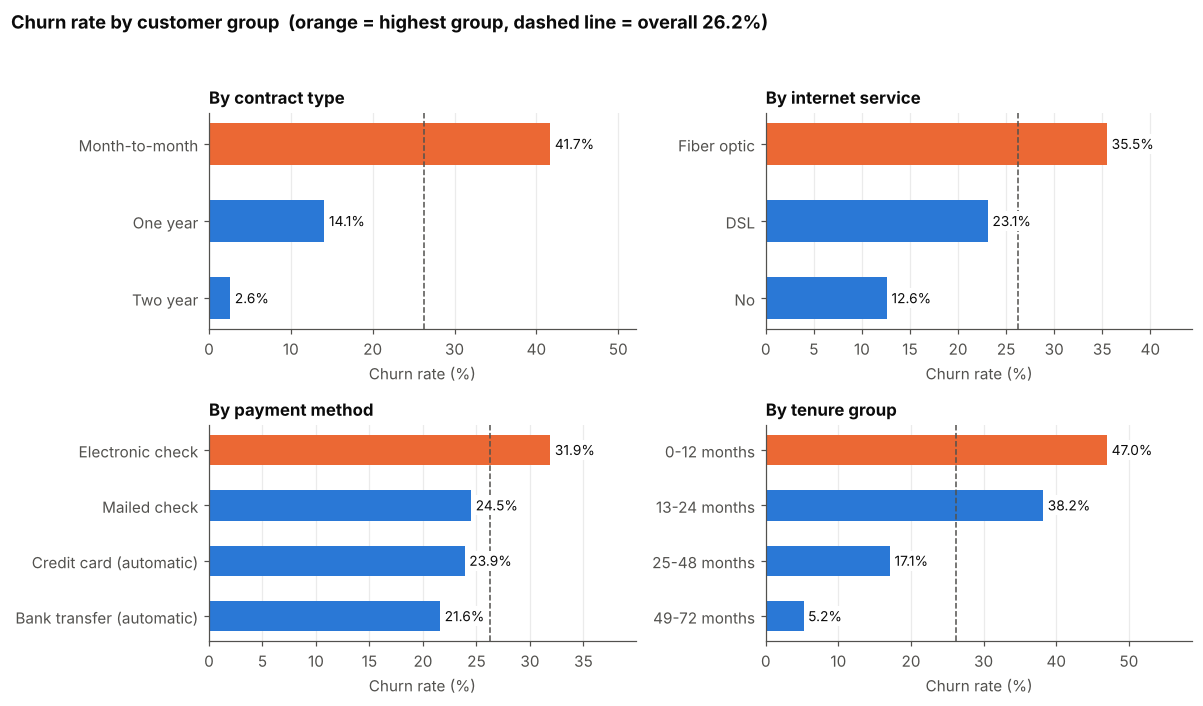

In [14]:
def draw_bar(ax, table, title):
    s = table["churn_rate_pct"].sort_values()
    colors = [ORANGE if v == s.max() else BLUE for v in s]
    bars = ax.barh(s.index.astype(str), s.values, color=colors, height=0.55)
    ax.bar_label(bars, fmt="%.1f%%", padding=3, color="#0b0b0b", fontsize=9,
                 bbox=dict(facecolor="white", edgecolor="none", pad=1.2))
    ax.axvline(churn_rate, color=MUTED, ls="--", lw=1)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold")
    ax.set_xlim(0, s.max() * 1.25)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Churn rate (%)")

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
draw_bar(axes[0, 0], by_contract, "By contract type")
draw_bar(axes[0, 1], by_internet, "By internet service")
draw_bar(axes[1, 0], by_payment,  "By payment method")
draw_bar(axes[1, 1], by_tenure,   "By tenure group")
fig.suptitle(f"Churn rate by customer group  (orange = highest group, dashed line = overall {churn_rate:.1f}%)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(IMG / "01_churn_by_group.png", bbox_inches="tight", facecolor="white")
plt.show()

### Chart 2 - Tenure and monthly charges

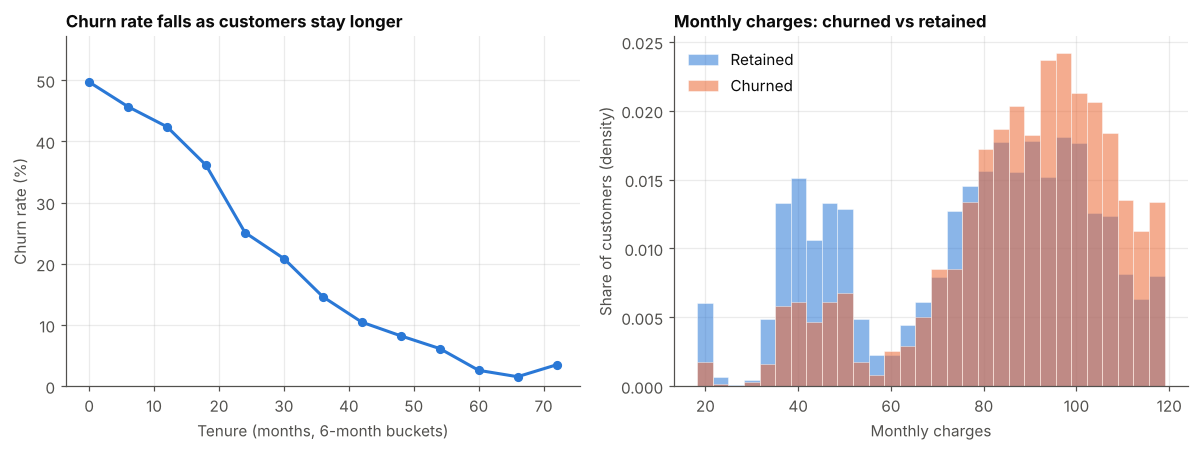

In [15]:
tenure_6m = (df.assign(tenure_bucket=(df["tenure"] // 6) * 6)
               .groupby("tenure_bucket")["Churn_flag"].mean() * 100)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

ax1.plot(tenure_6m.index, tenure_6m.values, color=BLUE, lw=2, marker="o", ms=5)
ax1.set_title("Churn rate falls as customers stay longer", loc="left", fontsize=11, fontweight="bold")
ax1.set_xlabel("Tenure (months, 6-month buckets)"); ax1.set_ylabel("Churn rate (%)")
ax1.set_ylim(0, tenure_6m.max() * 1.15)

for flag, colour, label in [(0, BLUE, "Retained"), (1, ORANGE, "Churned")]:
    ax2.hist(df.loc[df["Churn_flag"] == flag, "MonthlyCharges"], bins=30, density=True,
             alpha=0.55, color=colour, label=label, edgecolor="white", linewidth=0.5)
ax2.set_title("Monthly charges: churned vs retained", loc="left", fontsize=11, fontweight="bold")
ax2.set_xlabel("Monthly charges"); ax2.set_ylabel("Share of customers (density)")
ax2.legend(frameon=False)

fig.tight_layout()
fig.savefig(IMG / "02_tenure_and_charges.png", bbox_inches="tight", facecolor="white")
plt.show()

### Chart 3 - Where the risk is concentrated (contract x internet service)

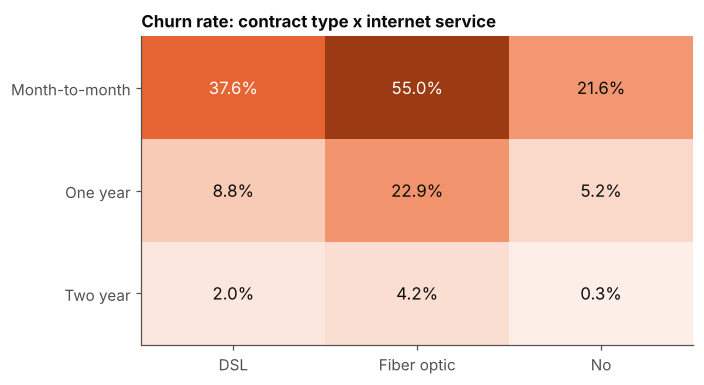

InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,37.6,55.0,21.6
One year,8.8,22.9,5.2
Two year,2.0,4.2,0.3


In [16]:
pivot = df.pivot_table(index="Contract", columns="InternetService", values="Churn_flag",
                       aggfunc="mean", observed=True) * 100
pivot = pivot.loc[["Month-to-month", "One year", "Two year"], ["DSL", "Fiber optic", "No"]]

seq = LinearSegmentedColormap.from_list("seq", ["#fdf0ea", "#f4a27f", "#eb6834", "#9c3a14"])
fig, ax = plt.subplots(figsize=(6.5, 3.6))
im = ax.imshow(pivot.values, cmap=seq, aspect="auto", vmin=0)
ax.set_xticks(range(pivot.shape[1]), pivot.columns); ax.set_yticks(range(pivot.shape[0]), pivot.index)
ax.grid(False)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        ax.text(j, i, f"{v:.1f}%", ha="center", va="center", fontsize=11,
                color="white" if v > pivot.values.max() * 0.6 else "#0b0b0b")
ax.set_title("Churn rate: contract type x internet service", loc="left", fontsize=11, fontweight="bold")
fig.tight_layout()
fig.savefig(IMG / "03_contract_internet_heatmap.png", bbox_inches="tight", facecolor="white")
plt.show()
pivot.round(1)

### Chart 4 - Correlation with churn

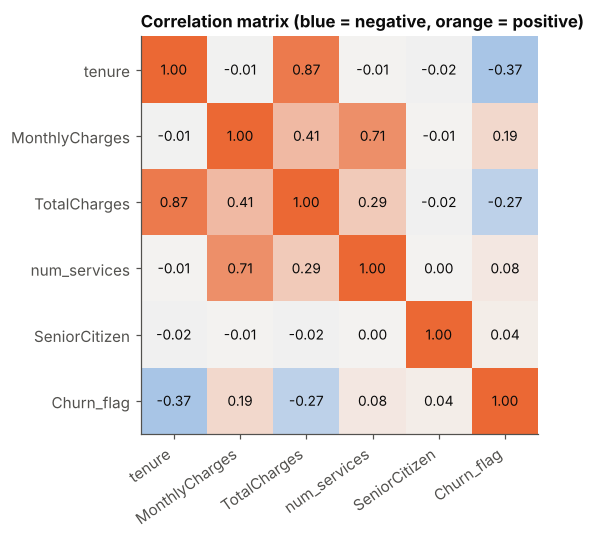

tenure           -0.37
TotalCharges     -0.27
SeniorCitizen     0.04
num_services      0.08
MonthlyCharges    0.19
Name: Churn_flag, dtype: float64

In [17]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "num_services", "SeniorCitizen", "Churn_flag"]
corr = df[num_cols].corr()

div = LinearSegmentedColormap.from_list("div", [BLUE, "#f4f3f1", ORANGE])
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.imshow(corr.values, cmap=div, vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), num_cols, rotation=35, ha="right"); ax.set_yticks(range(len(num_cols)), num_cols)
ax.grid(False)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=9, color="#0b0b0b")
ax.set_title("Correlation matrix (blue = negative, orange = positive)", loc="left", fontsize=11, fontweight="bold")
fig.tight_layout()
fig.savefig(IMG / "04_correlation.png", bbox_inches="tight", facecolor="white")
plt.show()
corr["Churn_flag"].drop("Churn_flag").sort_values().round(2)

## 7. High-risk customer segments

In [18]:
segments = (df.groupby(["Contract", "InternetService", "tenure_group"], observed=True)
              .agg(customers=("Churn_flag", "size"), churn_rate_pct=("Churn_flag", "mean"),
                   monthly_revenue=("MonthlyCharges", "sum")))
segments["churn_rate_pct"] = (segments["churn_rate_pct"] * 100).round(1)
top_segments = segments[segments["customers"] >= 100].sort_values("churn_rate_pct", ascending=False).head(5)
top_segments

customers  churn_rate_pct  \
Contract       InternetService tenure_group                              
Month-to-month Fiber optic     0-12 months         695            63.5   
                               13-24 months        515            57.7   
               DSL             0-12 months         546            44.5   
               Fiber optic     25-48 months        359            43.5   
               DSL             13-24 months        433            38.1   

                                             monthly_revenue  
Contract       InternetService tenure_group                   
Month-to-month Fiber optic     0-12 months          69082.76  
                               13-24 months         50579.12  
               DSL             0-12 months          43355.47  
               Fiber optic     25-48 months         35794.07  
               DSL             13-24 months         34761.83

In [19]:
risk = df[df["high_risk_profile"] == "Yes"]
print(f"High-risk profile (month-to-month and tenure <= 12 months): {len(risk):,} customers "
      f"({len(risk) / total_customers * 100:.1f}% of base)")
print(f"  churn rate: {risk['Churn_flag'].mean() * 100:.1f}%  vs  {df.loc[df['high_risk_profile'] == 'No', 'Churn_flag'].mean() * 100:.1f}% for everyone else")
print(f"  share of all churned customers: {risk['Churn_flag'].sum() / churned_customers * 100:.1f}%")

High-risk profile (month-to-month and tenure <= 12 months): 1,575 customers (22.4% of base)
  churn rate: 48.9%  vs  19.7% for everyone else
  share of all churned customers: 41.7%


## 8. Business insights (calculated from the data)

In [20]:
fib = by_internet.loc["Fiber optic", "churn_rate_pct"]
dsl = by_internet.loc["DSL", "churn_rate_pct"]
m2m = by_contract.loc["Month-to-month", "churn_rate_pct"]
two = by_contract.loc["Two year", "churn_rate_pct"]
echeck = by_payment.loc["Electronic check", "churn_rate_pct"]
others = df.loc[df["PaymentMethod"] != "Electronic check", "Churn_flag"].mean() * 100
tech_no  = by_tech.loc["No", "churn_rate_pct"]
tech_yes = by_tech.loc["Yes", "churn_rate_pct"]
first_year = by_tenure.loc["0-12 months", "churn_rate_pct"]
long_term = by_tenure.loc["49-72 months", "churn_rate_pct"]

print(f"1. Overall churn is {churn_rate:.1f}% - about {revenue_lost:,.0f} of monthly revenue ({revenue_lost / monthly_revenue * 100:.1f}%).")
print(f"2. Contract type is the strongest driver: month-to-month churn is {m2m:.1f}% vs {two:.1f}% on two-year plans ({m2m / two:.1f}x higher).")
print(f"3. Fiber optic customers churn at {fib:.1f}% vs {dsl:.1f}% for DSL.")
print(f"4. Electronic-check payers churn at {echeck:.1f}% vs {others:.1f}% for other payment methods.")
print(f"5. Customers without tech support churn at {tech_no:.1f}% vs {tech_yes:.1f}% with it.")
print(f"6. First-year customers churn at {first_year:.1f}% vs {long_term:.1f}% for customers with 49+ months of tenure.")
print(f"7. Month-to-month customers in their first year are {len(risk) / total_customers * 100:.0f}% of the base but {risk['Churn_flag'].sum() / churned_customers * 100:.0f}% of all churn.")

1. Overall churn is 26.2% - about 161,409 of monthly revenue (28.8%).
2. Contract type is the strongest driver: month-to-month churn is 41.7% vs 2.6% on two-year plans (16.0x higher).
3. Fiber optic customers churn at 35.5% vs 23.1% for DSL.
4. Electronic-check payers churn at 31.9% vs 23.3% for other payment methods.
5. Customers without tech support churn at 31.3% vs 27.2% with it.
6. First-year customers churn at 47.0% vs 5.2% for customers with 49+ months of tenure.
7. Month-to-month customers in their first year are 22% of the base but 42% of all churn.


### Recommendations
1. **Move month-to-month customers to longer contracts** with a small discount or free add-on, especially in the first 12 months.
2. **Fix the fiber-optic experience** (service quality, installation and billing complaints) since it churns far more than DSL.
3. **Bundle tech support and online security** for new customers - customers who have them leave less often.
4. **Nudge electronic-check customers to automatic payment** (bank transfer or card) with a one-time bill credit.
5. **Build an early-warning list** from the high-risk profile and call those customers before month 6.

## 9. Save the clean data and the summary table

In [21]:
df.to_csv("data/telco_churn_clean.csv", index=False)
summary = pd.concat({"Contract": by_contract, "InternetService": by_internet,
                     "PaymentMethod": by_payment, "TenureGroup": by_tenure}, names=["dimension", "group"]).reset_index()
summary.to_csv("data/churn_summary_by_group.csv", index=False)
print("Saved: data/telco_churn_clean.csv and data/churn_summary_by_group.csv")
print("Charts saved in the images/ folder:", sorted(p.name for p in IMG.glob("*.png")))

Saved: data/telco_churn_clean.csv and data/churn_summary_by_group.csv
Charts saved in the images/ folder: ['01_churn_by_group.png', '02_tenure_and_charges.png', '03_contract_internet_heatmap.png', '04_correlation.png']


## 10. Conclusion
In this dataset, churn is concentrated in **new, month-to-month, fiber-optic customers without support services who pay by electronic check**.
Targeting that group with contract upgrades, bundled support and automatic-payment incentives is the quickest way to protect monthly revenue.

**Skills shown:** data cleaning, `groupby` / `pivot_table`, `pd.cut` / `pd.qcut`, NumPy (`np.where`, `np.percentile`), correlation analysis,
Matplotlib charts, business storytelling.